# Wordle solver benchmark

The solver plays every possible answer (the 3,624-word madalynrose list), guessing from the 9,795-word joined list. This notebook plots the results.

The numbers come from `benchmark.py`, which takes about 12 minutes and writes `results/strategies.csv` and `results/openers.csv`. This notebook only reads those files and draws the charts, so it runs in seconds.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wordle_solver import WordleSolver, ALPHABET

strategies = pd.read_csv('results/strategies.csv')
openers = pd.read_csv('results/openers.csv', keep_default_na=False)

## 1. Strategies

Each strategy picks every guess, including the first. Games continue past six guesses, so the full distribution is visible; **won** counts games solved within six.

In [2]:
table = strategies[['strategy', 'win_rate', 'mean_guesses', 'worst']].copy()
table['win_rate'] = (100 * table['win_rate']).round(2).astype(str) + '%'
table['mean_guesses'] = table['mean_guesses'].round(3)
table.rename(columns={'win_rate': 'won in 6', 'mean_guesses': 'average guesses', 'worst': 'worst game'})

,strategy,won in 6,average guesses,worst game
0,entropy,100.0%,3.598,6
1,entropy (hard mode),97.57%,3.847,12
2,heatmap,96.72%,3.947,12
3,frequency,93.65%,4.442,11
4,random candidate,94.81%,4.361,14


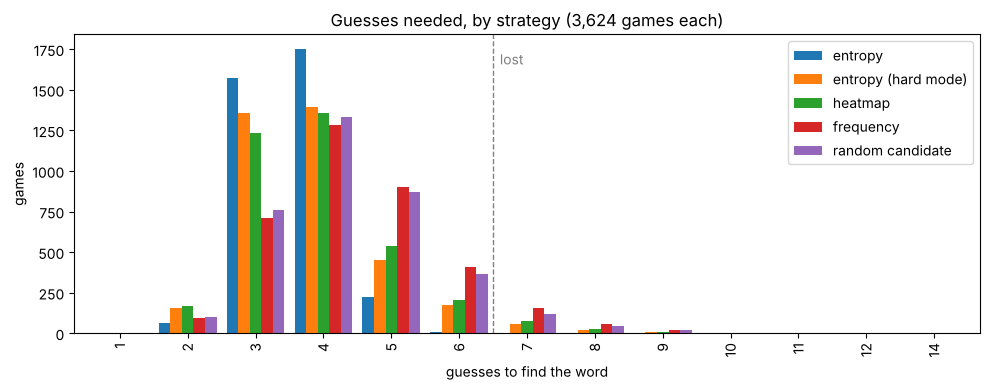

In [3]:
def parse(dist):
    return {int(k): int(v) for k, v in (pair.split(':') for pair in dist.split())}

dists = pd.DataFrame({row.strategy: parse(row.distribution) for row in strategies.itertuples()}).fillna(0).sort_index()
ax = dists.plot(kind='bar', figsize=(10, 4), width=0.85)
ax.axvline(5.5, color='gray', linestyle='--', linewidth=1)  # between 6 and 7 guesses
ax.text(5.6, ax.get_ylim()[1] * 0.9, 'lost', color='gray')
ax.set_xlabel('guesses to find the word')
ax.set_ylabel('games')
ax.set_title('Guesses needed, by strategy (3,624 games each)')
plt.tight_layout()
plt.show()

## 2. The heat map: where each letter sits

This is the statistic behind the `heatmap` strategy and the MadalynRose v1 notebook: the share of possible answers with each letter in each slot.
- `s` starts 17% of answers and ends 33%, because the list includes plurals.
- `e` is the fourth letter of 23%.
- `y` ends 9%.

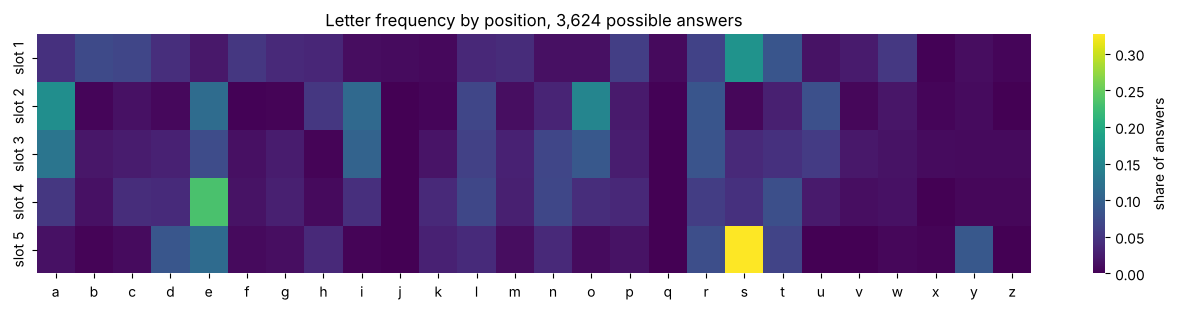

In [4]:
solver = WordleSolver()
codes = solver._codes
heat = pd.DataFrame(
    [np.bincount(codes[:, slot], minlength=26) / len(codes) for slot in range(5)],
    index=[f'slot {i}' for i in range(1, 6)], columns=list(ALPHABET),
)
plt.figure(figsize=(13, 3.2))
sns.heatmap(heat, cmap='viridis', cbar_kws={'label': 'share of answers'})
plt.title('Letter frequency by position, 3,624 possible answers')
plt.tight_layout()
plt.show()

## 3. Best starting words

**One-step scores.** Every allowed guess, scored as an opener against all 3,624 answers:
- *entropy*: the expected bits of information;
- *expected left*: how many candidates are expected to remain;
- *heatmap*: the heat-map score.

In [5]:
cols = ['entropy_rank', 'word', 'entropy', 'expected_left', 'heatmap', 'candidate', 'frequency']
openers[cols].head(15).round(3)

,entropy_rank,word,entropy,expected_left,heatmap,candidate,frequency
0,1,tares,6.359,70.503,2.897,True,1.90
1,2,rates,6.252,72.506,2.836,True,4.88
2,3,tears,6.227,80.462,2.720,True,4.47
3,4,tales,6.198,77.170,2.781,True,4.10
4,5,teras,6.189,81.473,2.670,False,1.58
5,6,tires,6.171,83.536,2.731,True,4.03
6,7,tries,6.167,83.284,2.726,True,4.53
7,8,arles,6.138,73.230,2.730,False,2.46
8,9,teals,6.127,86.340,2.637,True,1.61
9,10,saner,6.079,78.299,2.647,True,2.25


**Full games.** The top entropy openers, popular human openers, and the vowel-heavy words hand-checked in the NLTK CSV's `In Word List` column. Each one is played as the first guess in all 3,624 games, and the entropy strategy picks every guess after that.

In [6]:
played = openers[openers['mean_guesses'].astype(str) != ''].copy()
for c in ['mean_guesses', 'win_rate', 'worst']:
    played[c] = pd.to_numeric(played[c])
played = played.sort_values('mean_guesses')
show = played[['word', 'entropy_rank', 'entropy', 'mean_guesses', 'win_rate', 'worst']].copy()
show['win_rate'] = (100 * show['win_rate']).round(2).astype(str) + '%'
show.round(3).reset_index(drop=True)

,word,entropy_rank,entropy,mean_guesses,win_rate,worst
0,tares,1,6.359,3.598,100.0%,6.0
1,tires,6,6.171,3.614,100.0%,6.0
2,teals,9,6.127,3.621,100.0%,6.0
3,tales,4,6.198,3.622,100.0%,6.0
4,rates,2,6.252,3.623,100.0%,6.0
5,tries,7,6.167,3.623,100.0%,6.0
6,tears,3,6.227,3.624,100.0%,6.0
7,teras,5,6.189,3.632,100.0%,6.0
8,slate,11,6.078,3.634,100.0%,6.0
9,saner,10,6.079,3.640,100.0%,6.0


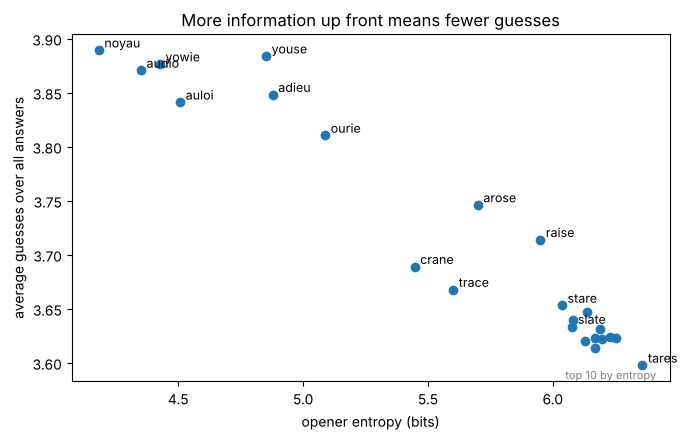

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(played['entropy'], played['mean_guesses'])
for row in played.itertuples():
    if row.entropy_rank > 10 or row.word == 'tares':  # the other top-10 openers overlap tares
        ax.annotate(row.word, (row.entropy, row.mean_guesses), xytext=(4, 2), textcoords='offset points', fontsize=9)
ax.set_xlabel('opener entropy (bits)')
ax.set_ylabel('average guesses over all answers')
ax.set_title('More information up front means fewer guesses')
ax.text(6.05, 3.585, 'top 10 by entropy', fontsize=8, color='gray')
plt.tight_layout()
plt.show()

## 4. Vowel-heavy openers

`adieu` and `audio` are popular openers because they test four vowels at once. But vowels are so common that they rarely come back gray, so these guesses split the answers into few, large groups.
- **Information:** they carry 4.2–5.1 bits, against 6.36 for `tares`, and rank between 1,750th and 6,821st of 9,795 openers.
- **Played in full:** they average 3.81–3.89 guesses, against 3.60 for `tares`. Four of the seven also lose one to seven of the 3,624 games.

In [8]:
vowel = openers[openers['word'].isin(['adieu', 'audio', 'ourie', 'auloi', 'yowie', 'youse', 'noyau'])]
vowel[['word', 'entropy_rank', 'entropy', 'expected_left']].round(3).sort_values('entropy_rank')

,word,entropy_rank,entropy,expected_left
1749,ourie,1750,5.088,177.984
2774,adieu,2775,4.878,188.827
2939,youse,2940,4.852,220.004
5011,auloi,5012,4.507,287.370
5518,yowie,5519,4.426,285.670
5913,audio,5914,4.350,322.204
6820,noyau,6821,4.182,353.589
